$\newcommand{\P}{\mathbf P}$
$\newcommand{\cov}{\operatorname{Cov}}$
$\newcommand{\E}{\mathbf E}$
$\newcommand{\var}{\operatorname{Var}}$
$\newcommand{\1}{\mathbf 1}$
$\newcommand{\R}{\mathbb R}$

#3.4. Expectation and Variance of Important Random Variables

If $X \sim \text{Multinomial}(n,p)$, then
$$ \var(X_i) = n p_i(1-p_i) $$
and
$$ \cov(X_i, X_j) = -n p_i p_j$$
if $i \ne j$. To remember the latter formula, think of the case where $X$ has two components. One way to derive $\cov(X_i, X_j)$ is to notice that $X_i + X_j \sim \text{Binomial}(n, p_i + p_j)$.

#3.5. Conditional Expectation

Note that
$$
\E \E (r(X,Y) | X ) = \E r(X,Y)
$$

#3.6. Moment Generating Functions
The MGF is also known as the Laplace transform

#3.8 Exercises

Exercise 3.1. Suppose we play a game where we start with $c$ dollars. On each play of the game you either double or halve your money, with equal probability. What is your expected fortune after $n$ trials?

Let $X_i$ be the  fortune  after $i$ trials. Then
$$\E(X_{i+1} | X_i =a) = \frac 12(\frac a2 + 2a) = \frac 54 a $$
and
$$ \E(X_{i+1}) = \frac 54 \E(X_i)$$
Thus
$$ \E(X_n) = \left ( \frac 54\right)^n c$$



Exercise 3.2. $\var(X) = 0$ if and only if there is a constant $c$ such that $\P(X = c) = 1$.

Exercise 3.3. If $X_1, \dots, X_n \sim \text{Uniform}(0,1)$ and $Y_n = \max(X_i)$, then $\E(Y_n) = 1 - 1/(n+1).$

Exercise 3.4. A particle starts at the origin of the real line and moves along the line in
jumps of one unit. For each jump, the probability is $p$ that the particle
will jump one unit to the left, and the probability is $1-p$ that the particle
will jump one unit to the right. Let $X_n$ be the position of the particle
after $n$ units.

$$ \E X_n = -n(2p - 1) $$
$$ \var(X_n) = 4n p(1-p)$$

Exercise 3.5. A fair coin is tossed until a head is obtained. The expected number of tosses is 2.

Exercise 3.6. If $Y = r(X)$ and $X$ is a discrete random variable, then
$\E Y = \sum_x r(x) \P(X = x)   $

Exercise 3.7. If $X$ is a continuous random variable with CDF $F$ with $\E|X| < \infty$ and $\P(X>0) = 1$, then $\E X = \int_0^\infty \P(X > x) \, dx$

Exercise 3.8. Let $X_1,\dots,X_n$ be IID with $\mu = \E X_1$, $\sigma^2 = \var X_1$. Then
$$
\E \bar X_n = \mu, \quad \var \bar X_n = \sigma^2 / n, \quad \E S_n^2 = \sigma^2,
$$
where
$$
S_n^2 = \frac{1}{n-1} \sum_{i=1}^{n} (X_i - \bar X_n)^2
$$

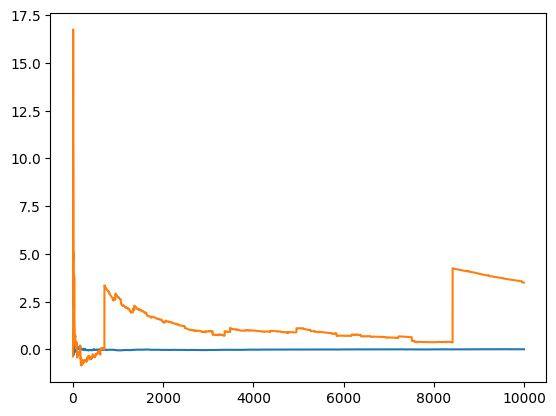

In [1]:
#Exercise 3.9.
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
x = rng.normal(0,1,size=10_000)
x_bar = x.cumsum() / np.arange(1,10_001)
plt.plot(np.arange(1,10_001), x_bar)

y = rng.standard_cauchy(size=10_000)
y_bar = y.cumsum() / np.arange(1,10_001)
plt.plot(np.arange(1,10_001), y_bar)
plt.show()


Aside on Cauchy distribution. $X \sim \text{Cauchy}$. The characteristic function is
$$
\begin{align*}
\E e^{i t X} &= \frac 1\pi \int_\R \frac {e^{itx}}{1 + x^2} \, dx \\
&= \frac 1\pi \int_\R \frac {e^{itx}}{(x+i) (x-i)} \, dx \\
\end{align*}
$$
Let $f(x)$ be the integrand. Case $t > 0$.  The residue of $f(z)$ at $z = i$ is
$$
\frac{e^{-t}}{2i}
$$
and so
$$
\E e^{i t X} = \frac 1\pi \cdot 2\pi i \cdot \frac{e^{-t}}{2i} = e^{-t}
$$
For $t < 0$ we would use the residue at $z = -i$ to obtain  $ \E e^{i t X}  = e^t$. For any $t$,
$$ \E e^{i t X} = e^{-|t|}$$
This implies, if $X_1, \dots, X_n \sim \text{Cauchy}$ are IID, that $\bar X_n \sim \text{Cauchy}$.

Exercise 3.10. If $X \sim N(0,1)$, the MGF of $X$ is $M_X(t) = e^{t^2/2}$. Let $Y = e^X$. Then
$$
\begin{align*}
&\E Y = \E e^{X} = M_X(1) = e^{1/2} \\
& \E Y^2 = \E e^{2X } = M_X(2) = e^{2} \\
&\var Y = e^2 - e
\end{align*}
$$

Exercise 3.11. Let $Y_1, Y_2, \dots$ be IID with $\P(Y_1 = 1) = \P(Y_1 = -1) = 1/2$.  Let $X_n = \sum_{i=1}^n Y_i$.

(a) $\E X_n = 0$

$\var X_n = 4n(1/2)(1-1/2) = n$

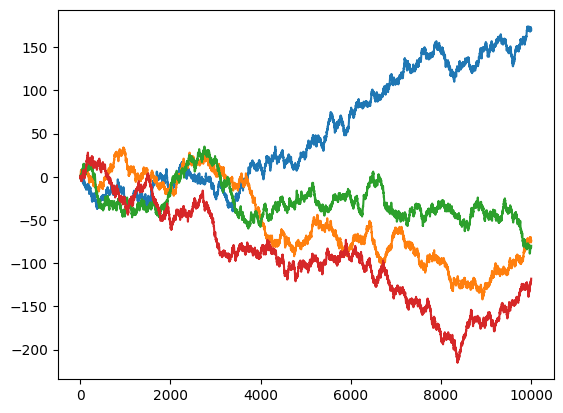

In [2]:
#(b)
y = [2 * rng.binomial(1,0.5,size = 10_000) - 1 for _ in range(4)]
x = [yi.cumsum() for yi in y]

for xi in x:
    plt.plot(np.arange(1, 10_001), xi)
plt.show()

Though $X_n$ has mean $0$, the variance is $n$ which is quite high. Though the distribution of $X_n$ is centered at $0$, individual observations  can be far from $0$ and the scale of deviations from $0$ grows like $n^{1/2}$.

Exercise 3.12. We use that $\E \text{Beta}(\alpha,\beta) = \alpha/(\alpha + \beta)$. Let $X \sim \text{Beta}(\alpha,\beta)$. Then $\E X^2$ is equal to

$$
\begin{align*}
\E X^2 &= \frac{\Gamma(\alpha+\beta)}{\Gamma(\alpha + \beta+1)}\frac{\Gamma(\alpha + \beta+1)}{\Gamma(\alpha+1)\Gamma(\beta)}\frac{\Gamma(\alpha+1)}{\Gamma(\alpha)}\int_0^1 x x^{(\alpha+1)-1}(1-x)^{\beta-1} \, dx \\
&= \frac{\Gamma(\alpha + \beta)}{\Gamma(\alpha+\beta+1)}\frac{\Gamma(\alpha+1)}{\Gamma(\alpha)}\E \text{Beta}(\alpha + 1, \beta) \\
&= \frac {\alpha(\alpha + 1)}{(\alpha + \beta)(\alpha + \beta + 1)}
\end{align*}
$$
and
$$
\begin{align*}
\var X &= \frac {\alpha(\alpha + 1)}{(\alpha + \beta)(\alpha + \beta + 1)}  -
\frac{\alpha^2}{(\alpha + \beta)^2} \\
&= \frac{\alpha(\alpha+1)(\alpha + \beta) - \alpha^2 (\alpha + \beta + 1)}{(\alpha + \beta)^2 (\alpha + \beta+1)} \\
&= \frac{(\alpha^2 + \alpha)(\alpha + \beta + 1) - (\alpha^2 + \alpha) - \alpha^2(\alpha + \beta + 1)}{(\alpha + \beta)^2 (\alpha + \beta+1)} \\
&= \frac{\alpha(\alpha + \beta + 1) - (\alpha^2 + \alpha) }{(\alpha + \beta)^2 (\alpha + \beta+1)} \\
&= \frac{\alpha\beta}{(\alpha + \beta)^2 (\alpha + \beta+1)}
\end{align*}
$$

Exercise 3.13. Suppose we generate a random variable $X$ in the following way. First, we flip a fair coin. If the coin is heads, take $X$ to have a $\mathrm{Unif}(0,1)$ distribution. If the coin is tails, take $X$ to have a $\mathrm{Unif}(3,4)$ distribution.

(a) $\E X = \frac 12 \E(X | H ) + \frac 12 \E(X | T) = \frac 14 + \frac 74 = 2$

(b) Let $Y$ be the result of the coin toss and $Z = \E(X|Y)$. Then $\P(Z = 1/2) = 1/2 $ and $\P(Z = 7/2) = 1/2$. Thus
$$ \var \E(X|Y) = \var Z = 9/4$$
Note that $\var (X|Y) = 1/12$ and so
$$ \E \var (X|Y) = 1/12.$$
Thus,
$$ \var X = 9/4 +  1/12 = 7/3$$
and
$$ \operatorname{SD} X = (7/3)^{1/2}$$

Exercise 3.14. Bilinearity of covariance

Exercise 3.15. Let
$$
f_{X,Y}(x,y)=
\begin{cases}
\frac{1}{3}(x+y), & 0 \le x \le 1,\; 0 \le y \le 2,\\
0, & \text{otherwise}.
\end{cases}
$$

$$\var(2X-3Y+8) = 4 \var X + 9 \var Y - 12 \cov(X,Y).$$

Now,
$$
\begin{align*}
3 \E X &= \int_0^2\int_0^1 (x^2 + xy) dxdy \\
&= \int_0^2 \left ( \frac 13 + \frac y2\right) dy \\
&= \frac 23 + 1 = \frac 53 \\
3\E X^2 &= \int_0^2\int_0^1 (x^3 + x^2y) dxdy \\
&= \int_0^2 \left ( \frac 14 + \frac y3 \right) dy \\
&= \frac 12 + \frac 23 = \frac 76 \\
3\E Y &= \int_0^2 \int_0^1 (xy + y^2) dx dy \\
&= \int_0^2 \left ( \frac y2 + y^2\right) dy \\
&= 1 + \frac 83 = \frac{11}3 \\
3 \E Y^2 &= \int_0^2 \int_0^1 (xy^2 + y^3) dx dy \\
&= \int_0^2 \left ( \frac{y^2}2 + y^3 \right) dy \\
&= \frac 43 + 4 = \frac{16}3 \\
3\E XY &= \int_0^2 \int_0^1 (x^2 y + y^2 x) dx dy  \\
&= \int_0^2 \left ( \frac{y}{3} + \frac{y^2}{2}\right ) dy \\
&= \frac{2}{3} + \frac 43 = 2
\end{align*}
$$

In [3]:
from fractions import Fraction
EX = Fraction(5,9)
EX2 = Fraction(7,18)
EY = Fraction(11,9)
EY2 = Fraction(16,9)
EXY = Fraction(2,3)

varX = EX2 - EX**2
varY = EY2 - EY**2
covXY = EXY - EX * EY

print('Var(2X - 3Y + 8) =', 4*varX + 9*varY-12*covXY)

Var(2X - 3Y + 8) = 245/81


Exercise 3.16.  $$ \E(r(X)s(Y) | X) = r(X) \E(s(Y) | X), \quad
 \E(r(X)|X) = r(X)$$

Exercise 3.17. $$ \var Y = \E \var (Y|X) + \var \E(Y|X) $$

Exercise 3.18. If $\E(X | Y) = c$ for some constant $c$, then
$$ \E X  = \E \E(X|Y) = c $$
and
$$ \E(XY) = \E\E(XY | Y) = \E \big(Y \E(X|Y)\big) = c \E Y = \E X \E Y.$$
Thus $X$ and $Y$ are uncorrelated


1 theory 0.5 0.08333 simulated 0.49674 0.08346


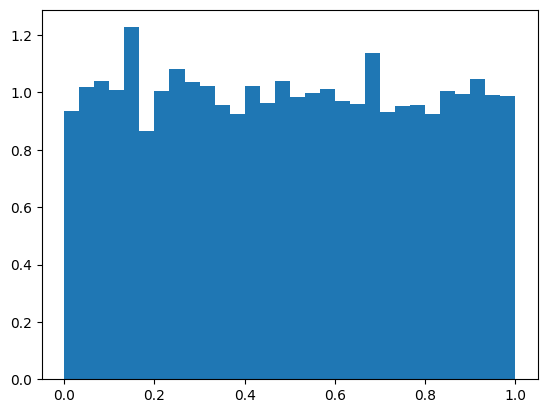

5 theory 0.5 0.01667 simulated 0.499 0.01697


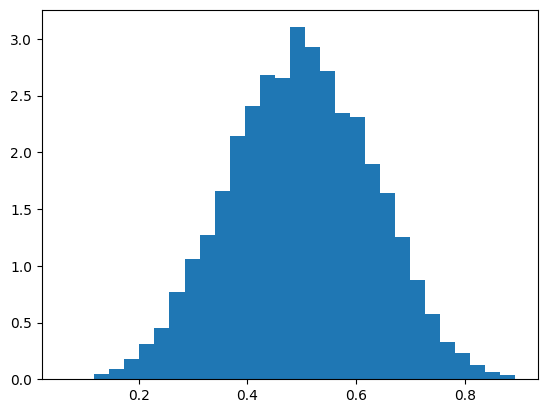

25 theory 0.5 0.00333 simulated 0.49992 0.00329


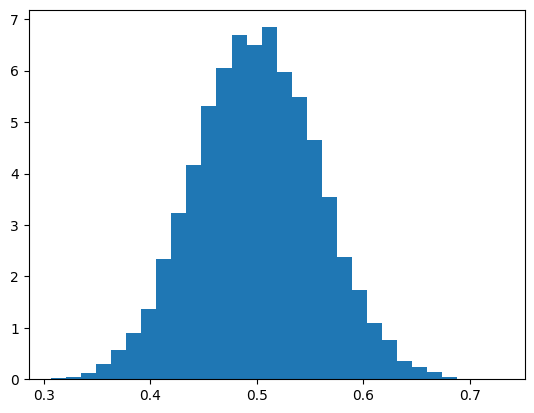

100 theory 0.5 0.00083 simulated 0.50037 0.00083


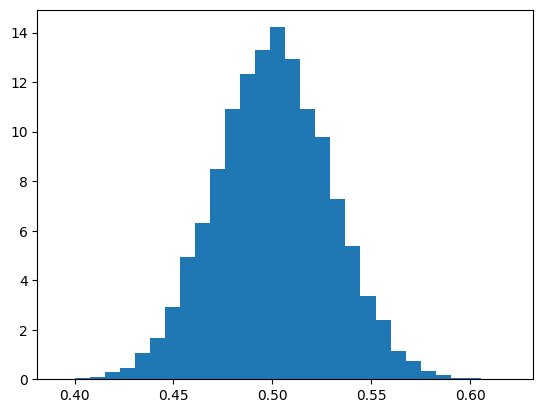

In [4]:
#Exercise 3.19.
#X_1,...,X_n ~ Uniform(0,1) and IID
#Simulate the distribution of X_n_bar for n = 1,5,25,100

x = [None] * 4
for i,s in enumerate([1,5,25,100]):
    x[i] = np.array([rng.uniform(0,1,size=s).mean() for _ in range(10_000)])

for i,n in zip(range(4),[1,5,25,100]):
    print(n, 'theory', 0.5, round(1/(12 * n),5), 'simulated', round(x[i].mean(),5), round(x[i].var(ddof=1),5))
    plt.hist(x[i],bins=30,density=True)
    plt.show()

Exercise 3.20. If $a$ is a constant vector and $X$ is a random vector, $\E a^T X = a^T \E X$ and $\var a^T X = a^T (\var X) a $. If $A$ is a constant matrix then $\E AX = A \E X$ and $\var AX = A (\var X) A^T$.

Exercise 3.21. If $X$ and $Y$ are random variables such that $\E(Y|X) = X$, then $ \E Y = \E X $ and
$$
\begin{align*}
\cov(X,Y) &= \E XY - \E X \E Y \\
&= \E\E(XY | X) - (\E X)^2 \\
&= \E X^2 - (\E X)^2 \\
&= \var X
\end{align*}
$$

Exercise 3.22. Let $X \sim \operatorname{Uniform}(0,1)$. Let $0 < a < b < 1$. Let

$$
Y =
\begin{cases}
1, & 0 < x < b, \\
0, & \text{otherwise},
\end{cases}
$$

and let

$$
Z =
\begin{cases}
1, & a < x < 1, \\
0, & \text{otherwise}.
\end{cases}
$$

(a) $\P(Y = 1, Z = 1) = b-a$

$\P(Y = 1) = b$

$\P(Z = 1) = 1-a$

If $b-a = b(1-a)$, then $0 = ab-a = a(b-1)$, but we have excluded $a = 0$ or $b = 1$, so $Y,Z$ are not independent.

(b) If $Z = 0$, then $Y = 1$. So $\E(Y|Z=0) = 1$.

If $Z = 1$, then $(Y|Z=1) \sim \text{Bernoulli}((b-a)/(1-a))$. So $\E(Y|Z=1) = (b-a)/(1-a)$. Hence

$$\E(Y|Z) = (1-Z) + Z \frac{b-a}{1-a}$$

Exercise 3.23. We note that $M_{a + bX}(t) = e^{at}M_X(bt)$

Poisson. $e^{\lambda(e^t-1)}$

Normal. $e^{\mu t + \sigma^2 t^2/2}$

Gamma. $1/(1-\beta t)^\alpha$

Exercise 3.24. Using that the moment generating function of $\text{Exp}(1)$ is $1/(1-t)$, we see that the moment generating function of $\text{Exp}(\beta)$ is $1/(1-\beta t)$. The moment generating function of $\text{Gamma}(\alpha, \beta)$ is $1/(1-\beta t)^\alpha$.